In [1]:
# ---LOADING IN DUSTMAPS--- #
# !! ONLY DO THIS ONCE !! # 
from dustmaps.config import config
config['data_dir'] = '/data/misfit/benlowe/xshooter/p115/dustmaps'

import dustmaps.sfd
dustmaps.sfd.fetch()

import dustmaps.bayestar
dustmaps.bayestar.fetch()

Checking existing file to see if MD5 sum matches ...
File exists. Not overwriting.
Checking existing file to see if MD5 sum matches ...
File exists. Not overwriting.
Checking existing file to see if MD5 sum matches ...
File exists. Not overwriting.


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import os
from astropy.io import fits
from astropy.table import Table
from __future__ import print_function
from astropy.coordinates import SkyCoord
from dustmaps.sfd import SFDQuery
from dustmaps.bayestar import BayestarQuery
import astropy.units as u

Loading in the literature Gaia DR3 data

In [2]:
lit_gaia_df = pd.read_csv('/data/misfit/benlowe/xshooter/lit_abund_data/all_lit_gaiadr3_final.csv')
display(lit_gaia_df)

,catalog,star_id,source_id,random_index,ra,dec,parallax,parallax_error,parallax_over_error,pmra,...,ebpminrp_gspphot,target_id,target_ra,target_dec,target_parallax,target_pm_ra,target_pm_dec,target_radial_velocity,epoch,target_separation (deg)
0,yong2013,52972-1213-507,811812182598263552,730540375,139.707938,37.740593,0.468856,0.039756,11.793310,-5.860822,...,0.0115,Gaia DR3 811812182598263552,139.707938,37.740593,0.4689,-5.8608,-33.2725,0.0000,2016.0,0.000000e+00
1,yong2013,53327-2044-515,290930261314166528,1215239180,25.150925,23.749406,1.066217,0.036955,28.851522,0.972496,...,0.2907,Gaia DR3 290930261314166528,25.150925,23.749406,1.0662,0.9725,-21.5905,0.0000,2016.0,0.000000e+00
2,yong2013,54142-2667-094,598558225898219776,772626430,132.902825,10.300841,0.422213,0.028656,14.734057,-8.773143,...,0.1108,Gaia DR3 598558225898219776,132.902825,10.300841,0.4222,-8.7731,-17.1661,0.0000,2016.0,1.776357e-15
3,yong2013,BS 16545-089,760839819965612928,344569189,171.114717,36.841186,0.644339,0.023748,27.132257,10.309770,...,0.0405,Gaia DR3 760839819965612928,171.114717,36.841186,0.6443,10.3098,-34.1174,0.0000,2016.0,0.000000e+00
4,yong2013,CS 30336-049,6795730493933072128,60677280,311.348047,-28.710012,0.062969,0.017374,3.624422,-1.727017,...,NaN,Gaia DR3 6795730493933072128,311.348047,-28.710012,0.0630,-1.7270,-8.1800,-235.8673,2016.0,0.000000e+00
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
310,yong2021,J224145.62-064643.0,2623363791014198656,990092424,340.440108,-6.778676,0.075457,0.018667,4.042358,1.869163,...,NaN,Gaia DR3 2623363791014198656,340.440108,-6.778676,0.0755,1.8692,-2.8984,-207.4769,2016.0,8.881784e-16
311,yong2021,J230525.31-213807.0,2398202677437168384,779426047,346.355546,-21.635311,0.286466,0.012346,23.202960,-1.075391,...,NaN,Gaia DR3 2398202677437168384,346.355546,-21.635311,0.2865,-1.0754,-15.1677,-17.3665,2016.0,0.000000e+00
312,yong2021,J230702.22-693718.5,6384594749521894400,286939962,346.759342,-69.621844,0.052283,0.015166,3.447462,1.060945,...,NaN,Gaia DR3 6384594749521894400,346.759342,-69.621844,0.0523,1.0609,-5.9018,153.2275,2016.0,0.000000e+00
313,yong2021,J232121.57-160505.4,2406023396270909440,605784975,350.339926,-16.084881,0.456265,0.013901,32.823170,17.221111,...,NaN,Gaia DR3 2406023396270909440,350.339926,-16.084881,0.4563,17.2211,3.4440,-40.4604,2016.0,0.000000e+00


Calculate reddening using the Shlegel dustmaps, then correcting using Casagrande et al. (2019):

 - If $|b| \geq 42$, then $E(B-V)_{\textrm{rescaled}} = E(B-V)_{\textrm{Schlegel}}$
 - If $4 < |b| < 42$, then $E(B-V)_{\textrm{rescaled}} = E(B-V)_{\textrm{Schlegel}} + 0.1 \times \textrm{log}_{10} (|b| - 3) - 0.16$
 - If $|b| \leq 4$, then $E(B-V)_{\textrm{rescaled}} = E(B-V)_{\textrm{Schlegel}} - 0.16$

In [3]:
# Calculating reddening values for every star using the Schlegel dustmaps
ebv_array = []
for i, row in lit_gaia_df.iterrows():
    
    # Getting the stellar parameters
    star = row['source_id']
    star_ra = row['ra']
    star_dec = row['dec']
    star_b = row['b']
    print(f"Running {i+1}/{len(lit_gaia_df)}")

    # Calculating E(B-V) using SFD dustmap    
    coords = SkyCoord(star_ra, star_dec, unit=(u.hourangle, u.deg), frame='icrs')
    sfd = SFDQuery()
    ebv = sfd(coords)
    
    # Applying corrections from Casagrande et al. (2019)
    # Case where |b| >= 42
    if abs(star_b) >= 42:
        ebv_corr = ebv
        
    # Case where 4 < |b| < 42
    if abs(star_b) > 4 and abs(star_b) < 42:
        ebv_corr = ebv + (0.1 * np.log10(abs(star_b) - 3)) - 0.16
        
    # Case where |b| <= 4
    if abs(star_b) <= 4:
        ebv_corr = ebv - 0.16
    
    # Storing into dictionary
    ebv_dict = {'source_id': star,
                'ra': star_ra,
                'dec': star_dec,
                'b': star_b,
                'ebv_schl': ebv,
                'ebv_corr': ebv_corr}

    ebv_array.append(ebv_dict)

# Convert list of dictionaries to DataFrame
ebv_df = pd.DataFrame(ebv_array)
display(ebv_df)

Running 1/315
Running 2/315
Running 3/315
Running 4/315
Running 5/315
Running 6/315
Running 7/315
Running 8/315
Running 9/315
Running 10/315
Running 11/315
Running 12/315
Running 13/315
Running 14/315
Running 15/315
Running 16/315
Running 17/315
Running 18/315
Running 19/315
Running 20/315
Running 21/315
Running 22/315
Running 23/315
Running 24/315
Running 25/315
Running 26/315
Running 27/315
Running 28/315
Running 29/315
Running 30/315
Running 31/315
Running 32/315
Running 33/315
Running 34/315
Running 35/315
Running 36/315
Running 37/315
Running 38/315
Running 39/315
Running 40/315
Running 41/315
Running 42/315
Running 43/315
Running 44/315
Running 45/315
Running 46/315
Running 47/315
Running 48/315
Running 49/315
Running 50/315
Running 51/315
Running 52/315
Running 53/315
Running 54/315
Running 55/315
Running 56/315
Running 57/315
Running 58/315
Running 59/315
Running 60/315
Running 61/315
Running 62/315
Running 63/315
Running 64/315
Running 65/315
Running 66/315
Running 67/315
Runn

,source_id,ra,dec,b,ebv_schl,ebv_corr
0,811812182598263552,139.707938,37.740593,44.520746,0.233259,0.233259
1,290930261314166528,25.150925,23.749406,-37.756369,0.044931,0.039034
2,598558225898219776,132.902825,10.300841,31.327749,0.020948,0.006169
3,760839819965612928,171.114717,36.841186,69.225489,0.222606,0.222606
4,6795730493933072128,311.348047,-28.710012,-36.253953,0.021958,0.014142
...,...,...,...,...,...,...
310,2623363791014198656,340.440108,-6.778676,-53.115825,0.047824,0.047824
311,2398202677437168384,346.355546,-21.635311,-65.293823,0.060906,0.060906
312,6384594749521894400,346.759342,-69.621844,-44.890214,0.254270,0.254270
313,2406023396270909440,350.339926,-16.084881,-66.387669,0.080765,0.080765


In [4]:
# Saving to csv
ebv_df.to_csv('/data/misfit/benlowe/xshooter/lit_abund_data/all_lit_ebv.csv', index=False)

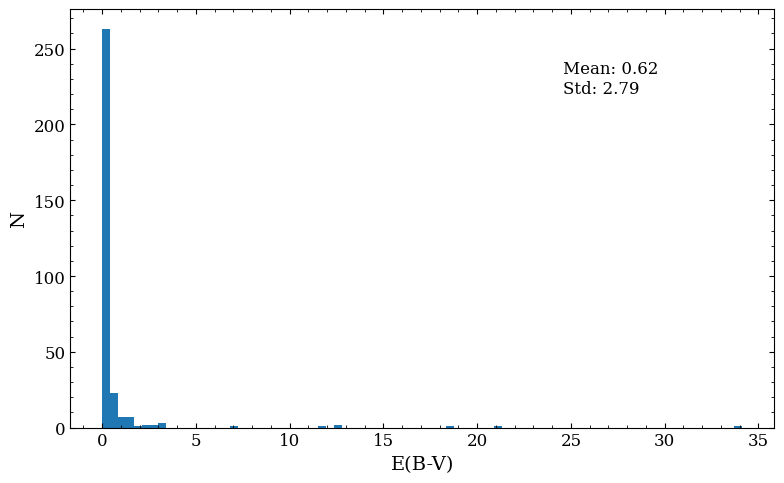

In [5]:
plt.figure(figsize=(8,5))
plt.hist(ebv_df['ebv_schl'], bins=80, label='Schlegel E(B-V)')
plt.xlabel('E(B-V)')
plt.ylabel('N')
plt.text(0.7, 0.8, f'Mean: {np.mean(ebv_df["ebv_schl"]):.2f}\nStd: {np.std(ebv_df["ebv_schl"]):.2f}', transform=plt.gca().transAxes)
plt.tight_layout()
plt.savefig('/data/misfit/benlowe/xshooter/p115/results/lit_results/ebv_schl_hist.png', dpi=300)

In [4]:
# Calculating reddening values for every star using the Schlegel dustmaps


# Getting the stellar parameters
star = 'star'
star_ra = 218.79722077902372
star_dec = -42.057368
star_b = 16.784917771513037

# Calculating E(B-V) using SFD dustmap    
coords = SkyCoord(star_ra, star_dec, unit=(u.hourangle, u.deg), frame='icrs')
sfd = SFDQuery()
ebv = sfd(coords)

# Applying corrections from Casagrande et al. (2019)
# Case where |b| >= 42
if abs(star_b) >= 42:
    ebv_corr = ebv
    
# Case where 4 < |b| < 42
if abs(star_b) > 4 and abs(star_b) < 42:
    ebv_corr = ebv + (0.1 * np.log10(abs(star_b) - 3)) - 0.16
    
# Case where |b| <= 4
if abs(star_b) <= 4:
    ebv_corr = ebv - 0.16

# Storing into dictionary
ebv_dict = {'source_id': star,
            'ra': star_ra,
            'dec': star_dec,
            'b': star_b,
            'ebv_schl': ebv,
            'ebv_corr': ebv_corr}

# Convert list of dictionaries to DataFrame
ebv_df = pd.DataFrame([ebv_dict])
display(ebv_df)

,source_id,ra,dec,b,ebv_schl,ebv_corr
0,star,218.797221,-42.057368,16.784918,0.016097,-0.029963
